# Unit 7 | Risk Modelling in Python

**Practical revisit prepared 18 October 2026**

This is a new, self-contained and executed demonstration informed by the Unit 7 readings. It uses new examples rather than reproducing the assigned exercises. It is **not a reconstruction of previously saved coursework or the original exercise outputs**.

Two small models explore different questions.

1. **Monte Carlo simulation** estimates the frequency of a supply disruption when two uncertain events must both occur.
2. **Bayesian updating** estimates the probability of a late delivery *after* a warning signal has been received.

The models use clearly identified **illustrative assumptions**, not operational data from Pampered Pets. The code is self-contained and reproducible through a fixed random seed. Its purpose is to demonstrate the methods and their limitations, not to produce credible company risk forecasts.

## 1. Monte Carlo simulation — supply disruption

**Scenario.** An illustrative delivery process experiences a material disruption if a primary supplier is late **and** the fallback arrangement fails. For each simulated delivery we assume:

- Probability of primary supplier delay = **0.18**
- Probability fallback fails, conditional on the primary supplier being late = **0.30**
- Both figures are **invented for this exercise**. No claim is made that they represent supplier performance.

We model the fallback event conditional on a primary delay, rather than treating the disruption outcome as a single unexplained percentage. The simple probability calculation provides a cross-check for the simulation.

Because this model has only two specified events, the disruption probability can be found analytically. The calculation is **0.18 × 0.30 = 0.054 (5.4%)**. Simulation is used here to examine random sampling and convergence, not because the simple probability requires it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 20261018
TRIALS = 60_000
PRIMARY_DELAY_PROB = 0.18
FALLBACK_FAIL_PROB_GIVEN_DELAY = 0.30

# A separate generator makes these results repeatable.
rng = np.random.default_rng(SEED)

# Each trial is an illustrative delivery. The fallback draw represents a
# 30% conditional failure chance when a primary delay occurs.
# Its outcome is ignored for deliveries that are not delayed.
primary_late = rng.random(TRIALS) < PRIMARY_DELAY_PROB
fallback_fails = rng.random(TRIALS) < FALLBACK_FAIL_PROB_GIVEN_DELAY
material_disruption = primary_late & fallback_fails

observed_rate = material_disruption.mean()
theoretical_rate = PRIMARY_DELAY_PROB * FALLBACK_FAIL_PROB_GIVEN_DELAY
standard_error = np.sqrt(observed_rate * (1.0 - observed_rate) / TRIALS)
ci_low = max(0.0, observed_rate - 1.96 * standard_error)
ci_high = min(1.0, observed_rate + 1.96 * standard_error)

print(f"Trials: {TRIALS:,} | Seed: {SEED}")
print(f"Simulated disruption rate: {observed_rate:.4%}")
print(f"Theoretical rate from assumptions: {theoretical_rate:.4%}")
print(f"Approximate 95% Monte Carlo sampling interval: {ci_low:.4%} to {ci_high:.4%}")

assert 0 <= observed_rate <= 1
assert abs(observed_rate - theoretical_rate) < 0.003, "Unexpected divergence; inspect simulation"


Trials: 60,000 | Seed: 20261018
Simulated disruption rate: 5.4717%
Theoretical rate from assumptions: 5.4000%
Approximate 95% Monte Carlo sampling interval: 5.2897% to 5.6536%


The 95% interval above is a **normal-approximation Monte Carlo sampling interval** for the frequency generated under these assumed probabilities. It describes simulation variability, not uncertainty about the real-world performance of a supplier. Increasing the number of simulated deliveries narrows sampling uncertainty, but cannot validate either input.

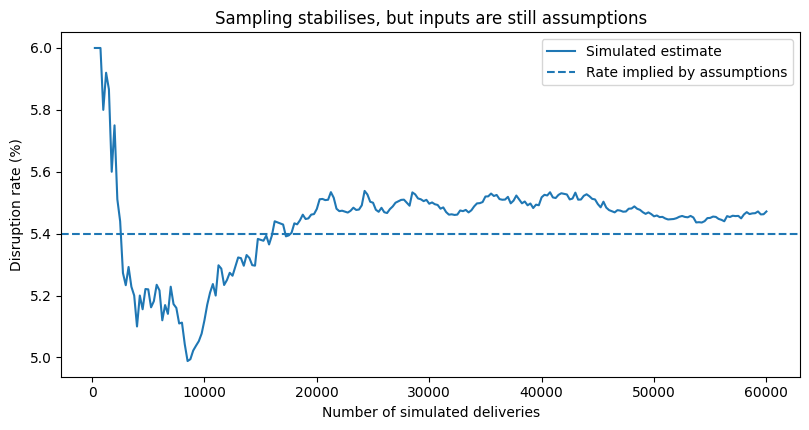

In [2]:
# Show convergence as more simulated deliveries are included.
checkpoints = np.arange(250, TRIALS + 1, 250)
running_rate = np.cumsum(material_disruption)[checkpoints - 1] / checkpoints
fig, ax = plt.subplots(figsize=(8.2, 4.4))
ax.plot(checkpoints, running_rate * 100, label="Simulated estimate")
ax.axhline(theoretical_rate * 100, linestyle="--", label="Rate implied by assumptions")
ax.set(xlabel="Number of simulated deliveries", ylabel="Disruption rate (%)",
       title="Sampling stabilises, but inputs are still assumptions")
ax.legend()
fig.tight_layout()
plt.show()


### Sensitivity to fallback reliability

Keeping the assumed primary-delay probability fixed, we vary the fallback-failure probability. This is not additional evidence of what any real supplier would do. It shows how much the answer depends on an uncertain safeguard.

In [3]:
fallback_scenarios = [0.15, 0.30, 0.50]
print("Fallback failure | Implied disruption probability")
for p_fallback in fallback_scenarios:
    probability = PRIMARY_DELAY_PROB * p_fallback
    print(f"{p_fallback:>15.0%} | {probability:>30.2%}")
assert np.isclose(PRIMARY_DELAY_PROB * 0.30, theoretical_rate)


Fallback failure | Implied disruption probability
            15% |                          2.70%
            30% |                          5.40%
            50% |                          9.00%


## 2. Bayesian updating — interpreting a supplier warning

Consider a separate question. A monitoring system reports that a delivery may be late. How should that signal change our assessment?

We specify the following illustrative probabilities.

- Prior probability that a delivery is late = **0.18**
- Probability of an alert when a delivery really is late = **0.80** (alert sensitivity)
- Probability of an alert when delivery is on time = **0.10** (false-positive rate)

Bayes' theorem combines the prior probability with the likelihood of an alert under each possibility. The values are **not measured performance statistics**.

In [4]:
def late_given_alert(prior_late, sensitivity, false_positive):
    """Return the posterior probability of delay after a positive alert."""
    if not all(0 <= p <= 1 for p in (prior_late, sensitivity, false_positive)):
        raise ValueError("Probabilities must lie between 0 and 1")
    true_positive = prior_late * sensitivity
    false_alarm = (1 - prior_late) * false_positive
    evidence = true_positive + false_alarm
    if evidence == 0:
        raise ValueError("A positive alert is impossible under these inputs")
    return true_positive / evidence

prior = 0.18
sensitivity = 0.80
false_positive = 0.10
posterior = late_given_alert(prior, sensitivity, false_positive)

print(f"Probability of late delivery before an alert: {prior:.2%}")
print(f"Probability of late delivery after an alert:  {posterior:.2%}")
assert np.isclose(posterior, 0.144 / (0.144 + 0.082))
assert posterior > prior


Probability of late delivery before an alert: 18.00%
Probability of late delivery after an alert:  63.72%


The alert increases the assessed probability of a late delivery. However, it does not establish certainty. The result would change if delays were rarer, or if alerts generated more false positives.

Prior chance of delay | Chance after positive alert
                  5% |                     29.63%
                 18% |                     63.72%
                 35% |                     81.16%


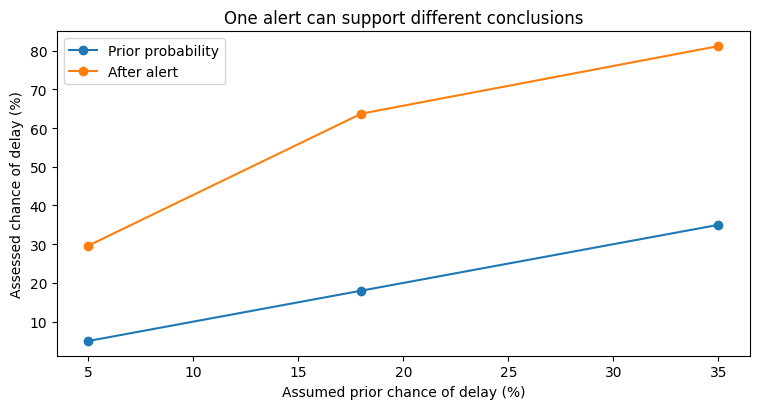

In [5]:
# Explore how a different prior changes the interpretation of the same alert.
priors = np.array([0.05, 0.18, 0.35])
posteriors = [late_given_alert(float(p), sensitivity, false_positive) for p in priors]
print("Prior chance of delay | Chance after positive alert")
for p, updated in zip(priors, posteriors):
    print(f"{p:>20.0%} | {updated:>26.2%}")

fig, ax = plt.subplots(figsize=(7.7, 4.2))
ax.plot(priors * 100, priors * 100, marker="o", label="Prior probability")
ax.plot(priors * 100, np.array(posteriors) * 100, marker="o", label="After alert")
ax.set(xlabel="Assumed prior chance of delay (%)", ylabel="Assessed chance of delay (%)",
       title="One alert can support different conclusions")
ax.legend()
fig.tight_layout()
plt.show()

assert all(0 <= value <= 1 for value in posteriors)


## 3. What this demonstrates and what remains unproven

**Monte Carlo** estimates an outcome frequency *given* assumed conditions. The simple two-event result can be calculated directly as 5.4%, so simulation is not necessary to derive it. Here repeated sampling demonstrates convergence and allows the simulated rate to be checked against that result. More complex models can make simulation useful, but repeated sampling cannot establish that the input probabilities reflect Pampered Pets. The sensitivity check also shows that changing fallback reliability can materially change the outcome even with identical code.

**Bayesian updating** answers a different question. An alert changes the probability assigned to an uncertain event, but its value depends on prior information and the alert's error rates. Neither a high posterior nor a stable simulation replaces observed delivery records or control testing.

The connection to the later Pampered Pets quantitative assessment is methodological rather than evidential. Its Unit 11 feedback questioned analyst-defined inputs and the reproducibility of the model. This notebook supplies a reproducible illustration of core techniques, **not a validation of that original assessment or evidence that its recovery objectives were met**. A stronger operational model would need measured delays, documented fallback performance, dependence between failures and a transparent validation process.

## Sources and execution

- Fizell, Z. (2022) [*How to Create a Monte Carlo Simulation using Python*](https://medium.com/data-science/how-to-create-a-monte-carlo-simulation-using-python-c24634a0978a). The article illustrates random sampling using a dice game. This notebook uses a separate, illustrative supply-disruption example rather than reproducing the article exercise.
- Downey, A.B. (2021) *Think Bayes*, 2nd edn. Sebastopol, CA: O’Reilly Media. [Chapter 1, Probability](https://allendowney.github.io/ThinkBayes2/chap01.html) and [Chapter 2, Bayes’ Theorem](https://allendowney.github.io/ThinkBayes2/chap02.html). The publisher gives **2021** as the publication year for the second edition. The module reading list refers to this material as **Downey (2022)**. The supplier-warning example is a new application of the introductory probability and Bayes’ theorem concepts, not a copy of the chapter exercises.

**To rerun** Open this `.ipynb` file in Jupyter Notebook, JupyterLab or VS Code with Python 3, `numpy` and `matplotlib` installed. Choose **Run All**. The fixed random seed makes the generated sample reproducible with the same NumPy random generator and version. Saved results were generated with Python 3.13.5, NumPy 2.3.5, and Matplotlib 3.10.8.
